# Machine Learning Lab – SVM

**Roll No.: CH.SC.U4CSE24257**

## 1. Import required libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

## 2. Generate random dataset following a quadratic distribution

In [2]:
np.random.seed(42)

n_samples = 300

X = np.random.uniform(-5, 5, n_samples)

noise = np.random.normal(0, 2, n_samples)

Y = X**2 + noise

labels = (Y > X**2).astype(int)

df = pd.DataFrame({
    'X': X,
    'Y': Y,
    'Class': labels
})

print("Generated Dataset:")
print(df.head())

print("\nDataset Shape:", df.shape)

Generated Dataset:
          X          Y  Class
0 -1.254599   1.665162      1
1  4.507143  19.011138      0
2  2.319939   9.670007      1
3  0.986585   2.241188      1
4 -3.439814   7.782032      0

Dataset Shape: (300, 3)


## 3. Visualize the generated dataset

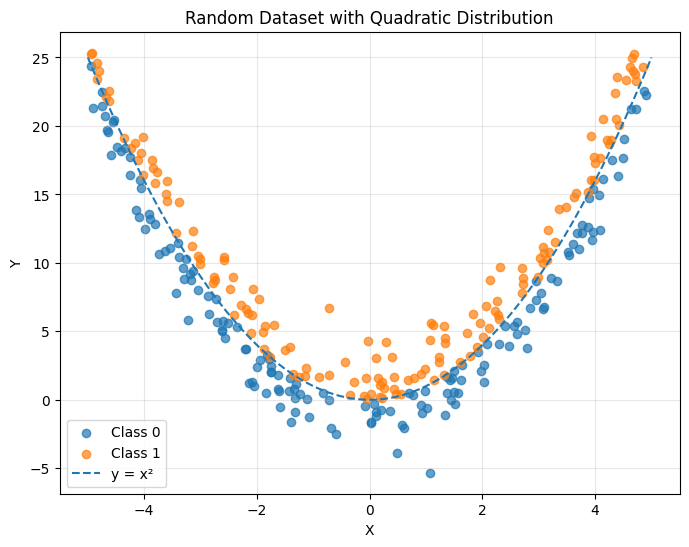

In [3]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df[df['Class'] == 0]['X'],
    df[df['Class'] == 0]['Y'],
    label='Class 0',
    alpha=0.7
)

plt.scatter(
    df[df['Class'] == 1]['X'],
    df[df['Class'] == 1]['Y'],
    label='Class 1',
    alpha=0.7
)

x_curve = np.linspace(-5, 5, 300)
plt.plot(
    x_curve,
    x_curve**2,
    linestyle='--',
    label='y = x²'
)

plt.xlabel('X')
plt.ylabel('Y')
plt.title('Random Dataset with Quadratic Distribution')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 4. Define input and target variables

In [4]:
X_data = df[['X', 'Y']]
y_data = df['Class']

print("Input Variables:")
print(X_data.head())

print("\nTarget Variable:")
print(y_data.head())

Input Variables:
          X          Y
0 -1.254599   1.665162
1  4.507143  19.011138
2  2.319939   9.670007
3  0.986585   2.241188
4 -3.439814   7.782032

Target Variable:
0    1
1    0
2    1
3    1
4    0
Name: Class, dtype: int64


## 5. Split the dataset into training and testing sets

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X_data,
    y_data,
    test_size=0.20,
    random_state=42,
    stratify=y_data
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))


Training Samples: 240
Testing Samples: 60


## 6. Create and train SVM model

In [6]:
model = SVC(
    kernel='poly',
    degree=2,
    C=1,
    gamma='scale'
)

model.fit(X_train, y_train)

print("\nSVM model trained successfully.")


SVM model trained successfully.


## 7. Make predictions

In [7]:
y_pred = model.predict(X_test)

print("\nPredictions:")
print(y_pred[:20])


Predictions:
[0 0 0 0 0 0 0 0 1 1 0 0 0 0 1 0 0 0 0 0]


## 8. Calculate model accuracy

In [8]:
accuracy = accuracy_score(y_test, y_pred)

print("\nAccuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")


Accuracy: 0.4666666666666667
Accuracy Percentage: 46.666666666666664 %


## 9. Display confusion matrix


Confusion Matrix:
[[22  8]
 [24  6]]


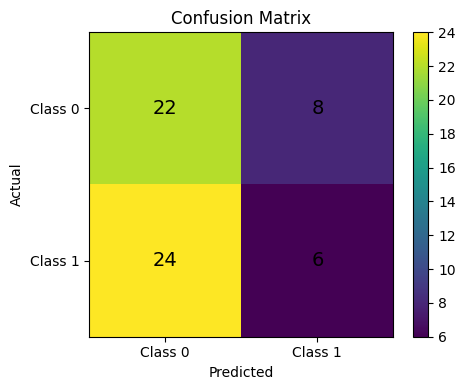

In [9]:
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

plt.figure(figsize=(5, 4))

plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0, 1], ['Class 0', 'Class 1'])
plt.yticks([0, 1], ['Class 0', 'Class 1'])

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha='center',
            va='center',
            fontsize=14
        )

plt.colorbar()
plt.tight_layout()
plt.show()

## 10. Display classification report

In [10]:
print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=['Class 0', 'Class 1']
    )
)


Classification Report:
              precision    recall  f1-score   support

     Class 0       0.48      0.73      0.58        30
     Class 1       0.43      0.20      0.27        30

    accuracy                           0.47        60
   macro avg       0.45      0.47      0.43        60
weighted avg       0.45      0.47      0.43        60



## 11. Visualize SVM decision boundary

c:\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


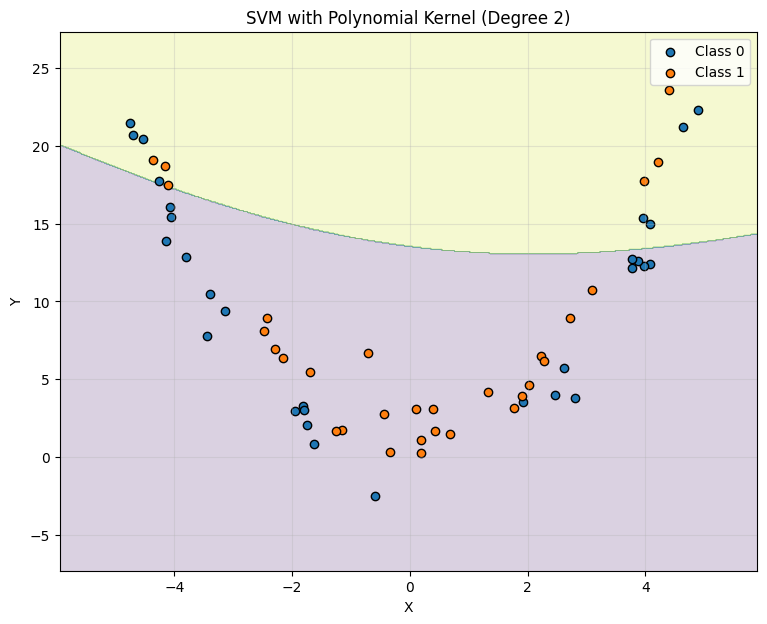

In [11]:
x_min = X_data['X'].min() - 1
x_max = X_data['X'].max() + 1
y_min = X_data['Y'].min() - 2
y_max = X_data['Y'].max() + 2

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 500),
    np.linspace(y_min, y_max, 500)
)

grid = np.c_[xx.ravel(), yy.ravel()]

Z = model.predict(grid)
Z = Z.reshape(xx.shape)

plt.figure(figsize=(9, 7))

plt.contourf(
    xx,
    yy,
    Z,
    alpha=0.2
)

plt.scatter(
    X_test[y_test == 0]['X'],
    X_test[y_test == 0]['Y'],
    label='Class 0',
    edgecolors='black'
)

plt.scatter(
    X_test[y_test == 1]['X'],
    X_test[y_test == 1]['Y'],
    label='Class 1',
    edgecolors='black'
)

plt.xlabel('X')
plt.ylabel('Y')
plt.title('SVM with Polynomial Kernel (Degree 2)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 12. Display support vectors

In [12]:
print("\nNumber of Support Vectors:")
print(model.n_support_)

print("\nTotal Support Vectors:")
print(len(model.support_))


Number of Support Vectors:
[ 99 100]

Total Support Vectors:
199


## 13. Predict a new data point

In [13]:
new_data = pd.DataFrame({
    'X': [2.0],
    'Y': [5.0]
})

new_prediction = model.predict(new_data)

print("\nNew Data Point:")
print(new_data)

print("\nPredicted Class:")

if new_prediction[0] == 0:
    print("Class 0")
else:
    print("Class 1")


New Data Point:
     X    Y
0  2.0  5.0

Predicted Class:
Class 0


## 14. Conclusion

In [14]:
print("\nSVM classification was successfully performed on a randomly generated")
print("dataset following a quadratic distribution.")
print("A polynomial kernel of degree 2 was used to model the nonlinear")
print("quadratic relationship between the variables.")
print("The model was evaluated using accuracy, confusion matrix,")
print("classification report, and the SVM decision boundary.")


SVM classification was successfully performed on a randomly generated
dataset following a quadratic distribution.
A polynomial kernel of degree 2 was used to model the nonlinear
quadratic relationship between the variables.
The model was evaluated using accuracy, confusion matrix,
classification report, and the SVM decision boundary.
